# Project StreamGuard
## Subscription Churn Prediction using Machine Learning

### Objective

The objective of Project StreamGuard is to develop an end-to-end machine learning pipeline for predicting customer churn in a subscription-based streaming service.

The project includes data cleaning, exploratory data analysis, feature engineering, preprocessing, feature selection, cross-validation, hyperparameter tuning, baseline model comparison, ensemble learning, and final model recommendation.

# Module 1: Data Exploration, Wrangling, and Cleaning

This module focuses on creating and exploring the customer subscription dataset, identifying missing values, handling numerical and categorical null values, detecting unrealistic outliers using the IQR method, and performing exploratory data analysis.

In [44]:
# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [45]:
# ============================================================
# CREATE SYNTHETIC STREAMING SUBSCRIPTION DATASET
# ============================================================

np.random.seed(42)

n_customers = 700

df = pd.DataFrame({
    "Age": np.random.randint(18, 70, n_customers),

    "Monthly_Charges": np.random.uniform(
        5, 50, n_customers
    ).round(2),

    "Watch_Hours_Per_Month": np.random.uniform(
        2, 150, n_customers
    ).round(2),

    "Login_Frequency": np.random.randint(
        1, 31, n_customers
    ),

    "Subscription_Months": np.random.randint(
        1, 61, n_customers
    ),

    "Support_Tickets": np.random.randint(
        0, 8, n_customers
    ),

    "Plan_Type": np.random.choice(
        ["Basic", "Standard", "Premium"],
        n_customers
    ),

    "Payment_Method": np.random.choice(
        ["Credit Card", "Debit Card", "UPI", "Net Banking"],
        n_customers
    ),

    "Device_Type": np.random.choice(
        ["Mobile", "Laptop", "Smart TV", "Tablet"],
        n_customers
    )
})

# Create a meaningful churn probability
churn_score = (
    0.06 * df["Monthly_Charges"]
    - 0.025 * df["Watch_Hours_Per_Month"]
    - 0.08 * df["Login_Frequency"]
    - 0.025 * df["Subscription_Months"]
    + 0.45 * df["Support_Tickets"]
    + np.random.normal(0, 1.5, n_customers)
)

churn_threshold = np.median(churn_score)

df["Churned"] = (
    churn_score > churn_threshold
).astype(int)

print("StreamGuard Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

StreamGuard Dataset Created Successfully!
Dataset Shape: (700, 10)


,Age,Monthly_Charges,Watch_Hours_Per_Month,Login_Frequency,Subscription_Months,Support_Tickets,Plan_Type,Payment_Method,Device_Type,Churned
0,56,15.65,110.62,20,55,6,Basic,Credit Card,Laptop,1
1,69,45.85,79.15,30,57,3,Premium,Net Banking,Tablet,0
2,46,31.63,130.49,20,60,4,Basic,Debit Card,Tablet,0
3,32,20.76,38.30,21,19,2,Basic,Net Banking,Smart TV,1
4,60,36.87,25.29,12,47,6,Standard,UPI,Tablet,1


In [46]:
# ============================================================
# INTRODUCE MISSING VALUES AND DATA ANOMALIES
# ============================================================

np.random.seed(42)

# Numerical missing values
charges_missing = np.random.choice(
    df.index, size=30, replace=False
)
df.loc[charges_missing, "Monthly_Charges"] = np.nan

watch_missing = np.random.choice(
    df.index, size=25, replace=False
)
df.loc[watch_missing, "Watch_Hours_Per_Month"] = np.nan

login_missing = np.random.choice(
    df.index, size=20, replace=False
)
df.loc[login_missing, "Login_Frequency"] = np.nan

# Categorical missing values
plan_missing = np.random.choice(
    df.index, size=20, replace=False
)
df.loc[plan_missing, "Plan_Type"] = np.nan

payment_missing = np.random.choice(
    df.index, size=15, replace=False
)
df.loc[payment_missing, "Payment_Method"] = np.nan

# Introduce unrealistic monthly charge anomalies
valid_indices = df.dropna(
    subset=["Monthly_Charges"]
).index

outlier_indices = np.random.choice(
    valid_indices,
    size=8,
    replace=False
)

df.loc[outlier_indices, "Monthly_Charges"] = [
    500,
    650,
    800,
    1000,
    750,
    900,
    1200,
    1500
]

print("Missing values and anomalies introduced successfully!")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing values and anomalies introduced successfully!

Missing Values:
Age                       0
Monthly_Charges          30
Watch_Hours_Per_Month    25
Login_Frequency          20
Subscription_Months       0
Support_Tickets           0
Plan_Type                20
Payment_Method           15
Device_Type               0
Churned                   0
dtype: int64

Dataset Shape: (700, 10)


In [47]:
# ============================================================
# INITIAL DATA EXPLORATION
# ============================================================

print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nChurn Distribution:")
print(df["Churned"].value_counts())

print("\nChurn Percentage:")
print(
    (df["Churned"].value_counts(normalize=True) * 100).round(2)
)

Dataset Shape: (700, 10)

Data Types:
Age                        int64
Monthly_Charges          float64
Watch_Hours_Per_Month    float64
Login_Frequency          float64
Subscription_Months        int64
Support_Tickets            int64
Plan_Type                 object
Payment_Method            object
Device_Type               object
Churned                    int64
dtype: object

Missing Values:
Age                       0
Monthly_Charges          30
Watch_Hours_Per_Month    25
Login_Frequency          20
Subscription_Months       0
Support_Tickets           0
Plan_Type                20
Payment_Method           15
Device_Type               0
Churned                   0
dtype: int64

Statistical Summary:


,Age,Monthly_Charges,Watch_Hours_Per_Month,Login_Frequency,Subscription_Months,Support_Tickets,Churned
count,700.000000,670.000000,675.000000,680.000000,700.000000,700.000000,700.000000
mean,44.217143,38.385328,74.670815,16.007353,31.192857,3.392857,0.500000
std,14.935483,102.358516,41.577166,8.630269,17.255920,2.274120,0.500358
min,18.000000,5.010000,2.050000,1.000000,1.000000,0.000000,0.000000
25%,32.000000,17.235000,37.705000,8.750000,17.000000,1.000000,0.000000
50%,45.000000,28.595000,73.930000,16.000000,32.000000,3.000000,0.500000
75%,56.000000,38.945000,109.715000,24.000000,46.000000,5.000000,1.000000
max,69.000000,1500.000000,149.330000,30.000000,60.000000,7.000000,1.000000



Churn Distribution:
Churned
1    350
0    350
Name: count, dtype: int64

Churn Percentage:
Churned
1    50.0
0    50.0
Name: proportion, dtype: float64


In [48]:
# ============================================================
# MISSING VALUE IMPUTATION
# ============================================================

numerical_missing_columns = [
    "Monthly_Charges",
    "Watch_Hours_Per_Month",
    "Login_Frequency"
]

for column in numerical_missing_columns:

    median_value = df[column].median()

    df[column] = df[column].fillna(
        median_value
    )

    print(
        f"{column} filled with median: "
        f"{median_value:.2f}"
    )


categorical_missing_columns = [
    "Plan_Type",
    "Payment_Method"
]

for column in categorical_missing_columns:

    mode_value = df[column].mode()[0]

    df[column] = df[column].fillna(
        mode_value
    )

    print(
        f"{column} filled with mode: "
        f"{mode_value}"
    )


print("\nMissing Values After Imputation:")
print(df.isnull().sum())

print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)

Monthly_Charges filled with median: 28.59
Watch_Hours_Per_Month filled with median: 73.93
Login_Frequency filled with median: 16.00
Plan_Type filled with mode: Basic
Payment_Method filled with mode: Net Banking

Missing Values After Imputation:
Age                      0
Monthly_Charges          0
Watch_Hours_Per_Month    0
Login_Frequency          0
Subscription_Months      0
Support_Tickets          0
Plan_Type                0
Payment_Method           0
Device_Type              0
Churned                  0
dtype: int64

Total Missing Values: 0


In [49]:
# ============================================================
# IQR OUTLIER DETECTION - MONTHLY CHARGES
# ============================================================

Q1 = df["Monthly_Charges"].quantile(0.25)
Q3 = df["Monthly_Charges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

charge_outliers = df[
    (df["Monthly_Charges"] < lower_bound) |
    (df["Monthly_Charges"] > upper_bound)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))

print(
    "Lower Bound:",
    round(lower_bound, 2)
)

print(
    "Upper Bound:",
    round(upper_bound, 2)
)

print(
    "\nNumber of Monthly Charge Outliers:",
    len(charge_outliers)
)

display(
    charge_outliers[
        [
            "Monthly_Charges",
            "Plan_Type",
            "Churned"
        ]
    ].sort_values(
        "Monthly_Charges",
        ascending=False
    )
)

Q1: 17.89
Q3: 38.56
IQR: 20.68
Lower Bound: -13.13
Upper Bound: 69.57

Number of Monthly Charge Outliers: 8


,Monthly_Charges,Plan_Type,Churned
20,1500.0,Premium,1
17,1200.0,Standard,0
655,1000.0,Basic,1
41,900.0,Basic,1
60,800.0,Premium,0
272,750.0,Premium,1
259,650.0,Standard,1
671,500.0,Standard,0


In [50]:
# ============================================================
# REMOVE EXTREME MONTHLY CHARGE OUTLIERS
# ============================================================

rows_before = len(df)

df = df[
    (df["Monthly_Charges"] >= lower_bound) &
    (df["Monthly_Charges"] <= upper_bound)
].copy()

df.reset_index(
    drop=True,
    inplace=True
)

rows_after = len(df)

print("Rows Before Cleaning:", rows_before)

print(
    "Rows Removed:",
    rows_before - rows_after
)

print("Rows After Cleaning:", rows_after)

print(
    "Total Missing Values:",
    df.isnull().sum().sum()
)

Rows Before Cleaning: 700
Rows Removed: 8
Rows After Cleaning: 692
Total Missing Values: 0


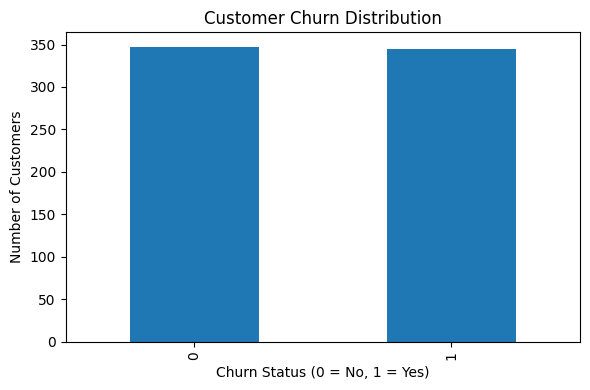

<Figure size 700x500 with 0 Axes>

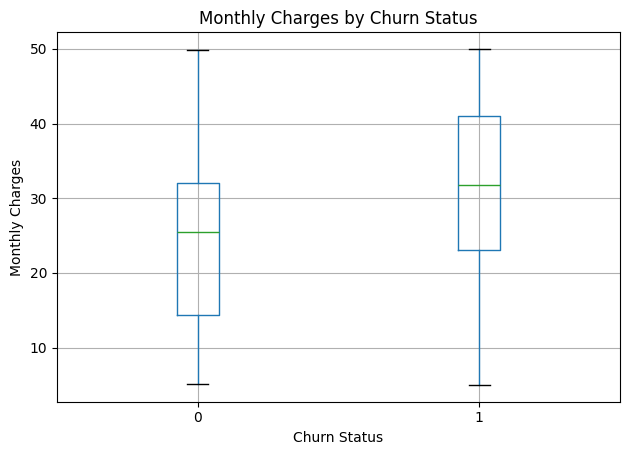

<Figure size 700x500 with 0 Axes>

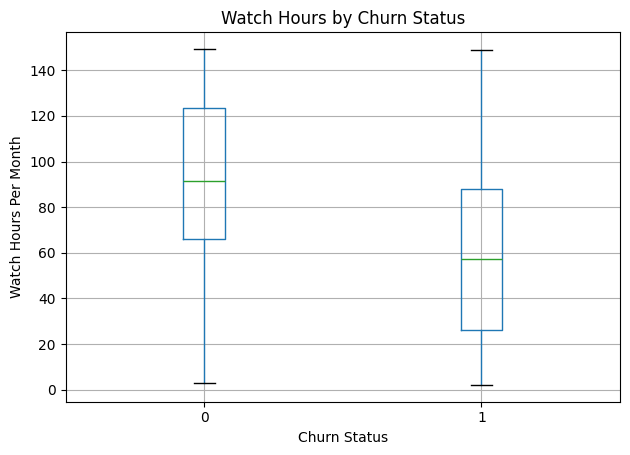

<Figure size 700x500 with 0 Axes>

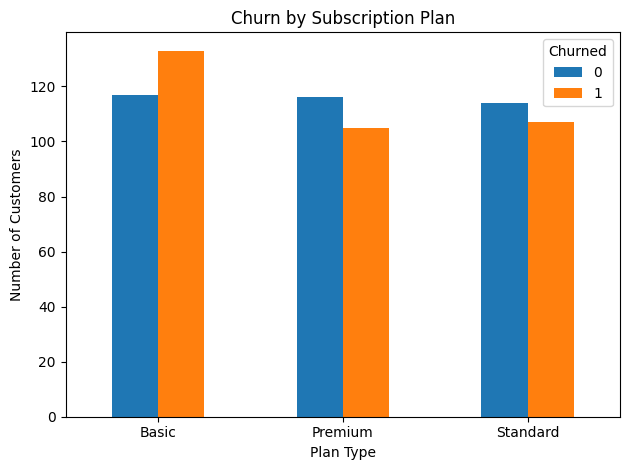

In [51]:
# ============================================================
# EXPLORATORY DATA ANALYSIS
# ============================================================

# Churn distribution
plt.figure(figsize=(6, 4))

df["Churned"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# Monthly charges by churn
plt.figure(figsize=(7, 5))

df.boxplot(
    column="Monthly_Charges",
    by="Churned"
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


# Watch hours by churn
plt.figure(figsize=(7, 5))

df.boxplot(
    column="Watch_Hours_Per_Month",
    by="Churned"
)

plt.title("Watch Hours by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Watch Hours Per Month")

plt.tight_layout()
plt.show()


# Subscription plan distribution
plt.figure(figsize=(7, 5))

pd.crosstab(
    df["Plan_Type"],
    df["Churned"]
).plot(
    kind="bar"
)

plt.title("Churn by Subscription Plan")
plt.xlabel("Plan Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [52]:
# ============================================================
# MODULE 1 FINAL CHECK
# ============================================================

print("Clean Dataset Shape:", df.shape)

print(
    "Total Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate Rows:",
    df.duplicated().sum()
)

print("\nFinal Churn Distribution:")
print(df["Churned"].value_counts())

print("\nModule 1 Completed Successfully!")

Clean Dataset Shape: (692, 10)
Total Missing Values: 0
Duplicate Rows: 0

Final Churn Distribution:
Churned
0    347
1    345
Name: count, dtype: int64

Module 1 Completed Successfully!


# Module 2: Feature Engineering, Encoding, and Scaling

This module transforms the cleaned subscription dataset into a machine-learning-ready format. It includes domain-driven feature engineering, One-Hot Encoding of categorical variables, and Z-Score Standardization of continuous numerical features.


In [53]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Engagement Score
# Higher watch hours and login frequency indicate
# stronger customer engagement.

df["Engagement_Score"] = (
    df["Watch_Hours_Per_Month"] *
    df["Login_Frequency"]
) / 100


# Support Intensity
# Measures customer support issues relative to
# subscription duration.

df["Support_Intensity"] = (
    df["Support_Tickets"] /
    (df["Subscription_Months"] + 1)
)


print("New Features Created Successfully!")

print("\nNew Feature Summary:")
display(
    df[
        [
            "Watch_Hours_Per_Month",
            "Login_Frequency",
            "Engagement_Score",
            "Support_Tickets",
            "Subscription_Months",
            "Support_Intensity"
        ]
    ].head()
)

New Features Created Successfully!

New Feature Summary:


,Watch_Hours_Per_Month,Login_Frequency,Engagement_Score,Support_Tickets,Subscription_Months,Support_Intensity
0,110.62,20.0,22.1240,6,55,0.107143
1,79.15,30.0,23.7450,3,57,0.051724
2,130.49,20.0,26.0980,4,60,0.065574
3,38.30,21.0,8.0430,2,19,0.100000
4,25.29,12.0,3.0348,6,47,0.125000


In [54]:
# ============================================================
# SEPARATE FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=["Churned"]
)

y = df["Churned"]

print("Feature Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Dataset Shape: (692, 11)
Target Shape: (692,)

Feature Columns:
['Age', 'Monthly_Charges', 'Watch_Hours_Per_Month', 'Login_Frequency', 'Subscription_Months', 'Support_Tickets', 'Plan_Type', 'Payment_Method', 'Device_Type', 'Engagement_Score', 'Support_Intensity']

Target Distribution:
Churned
0    347
1    345
Name: count, dtype: int64


In [55]:
# ============================================================
# IDENTIFY FEATURE TYPES
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()


print("Numerical Features:")
for feature in numerical_features:
    print("-", feature)


print("\nCategorical Features:")
for feature in categorical_features:
    print("-", feature)

Numerical Features:
- Age
- Monthly_Charges
- Watch_Hours_Per_Month
- Login_Frequency
- Subscription_Months
- Support_Tickets
- Engagement_Score
- Support_Intensity

Categorical Features:
- Plan_Type
- Payment_Method
- Device_Type


In [56]:
# ============================================================
# ONE-HOT ENCODING + Z-SCORE STANDARDIZATION
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),

        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)


X_processed = preprocessor.fit_transform(X)


print(
    "Original Feature Shape:",
    X.shape
)

print(
    "Processed Feature Shape:",
    X_processed.shape
)

Original Feature Shape: (692, 11)
Processed Feature Shape: (692, 19)


In [57]:
# ============================================================
# GET FINAL FEATURE NAMES
# ============================================================

encoded_categorical_features = (
    preprocessor
    .named_transformers_["cat"]
    .get_feature_names_out(
        categorical_features
    )
)

all_feature_names = (
    numerical_features
    + list(encoded_categorical_features)
)


print(
    "Total Processed Features:",
    len(all_feature_names)
)

print("\nProcessed Feature Names:")

for feature in all_feature_names:
    print("-", feature)

Total Processed Features: 19

Processed Feature Names:
- Age
- Monthly_Charges
- Watch_Hours_Per_Month
- Login_Frequency
- Subscription_Months
- Support_Tickets
- Engagement_Score
- Support_Intensity
- Plan_Type_Basic
- Plan_Type_Premium
- Plan_Type_Standard
- Payment_Method_Credit Card
- Payment_Method_Debit Card
- Payment_Method_Net Banking
- Payment_Method_UPI
- Device_Type_Laptop
- Device_Type_Mobile
- Device_Type_Smart TV
- Device_Type_Tablet


In [58]:
# ============================================================
# CREATE PROCESSED DATAFRAME
# ============================================================

X_processed_df = pd.DataFrame(
    X_processed,
    columns=all_feature_names,
    index=X.index
)


print(
    "Processed Dataset Shape:",
    X_processed_df.shape
)

display(
    X_processed_df.head()
)

Processed Dataset Shape: (692, 19)


,Age,Monthly_Charges,Watch_Hours_Per_Month,Login_Frequency,Subscription_Months,Support_Tickets,Engagement_Score,Support_Intensity,Plan_Type_Basic,Plan_Type_Premium,Plan_Type_Standard,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI,Device_Type_Laptop,Device_Type_Mobile,Device_Type_Smart TV,Device_Type_Tablet
0,0.791241,-0.972167,0.883898,0.468513,1.386469,1.153203,1.039130,-0.259311,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1.662797,1.433257,0.109864,1.644468,1.502631,-0.170207,1.205164,-0.395699,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.120813,0.300637,1.372619,0.468513,1.676873,0.270929,1.446176,-0.361615,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.817786,-0.565157,-0.894880,0.586108,-0.704440,-0.611344,-0.403148,-0.276890,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1.059412,0.718001,-1.214873,-0.472251,0.921823,1.153203,-0.916124,-0.215364,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [59]:
# ============================================================
# VERIFY Z-SCORE STANDARDIZATION
# ============================================================

scaled_numerical_data = X_processed_df[
    numerical_features
]

verification = pd.DataFrame({
    "Mean": scaled_numerical_data.mean(),
    "Standard Deviation": scaled_numerical_data.std(ddof=0)
}).round(4)


print("Standardization Verification:")

display(verification)

Standardization Verification:


,Mean,Standard Deviation
Age,0.0,1.0
Monthly_Charges,-0.0,1.0
Watch_Hours_Per_Month,0.0,1.0
Login_Frequency,-0.0,1.0
Subscription_Months,0.0,1.0
Support_Tickets,0.0,1.0
Engagement_Score,-0.0,1.0
Support_Intensity,0.0,1.0


In [60]:
# ============================================================
# MODULE 2 FINAL CHECK
# ============================================================

print(
    "Original Dataset Shape:",
    df.shape
)

print(
    "Processed Feature Shape:",
    X_processed_df.shape
)

print(
    "Target Shape:",
    y.shape
)

print(
    "\nMissing Values in Processed Data:",
    X_processed_df.isnull().sum().sum()
)

print(
    "Infinite Values:",
    np.isinf(
        X_processed_df.to_numpy()
    ).sum()
)

print("\nModule 2 Completed Successfully!")

Original Dataset Shape: (692, 12)
Processed Feature Shape: (692, 19)
Target Shape: (692,)

Missing Values in Processed Data: 0
Infinite Values: 0

Module 2 Completed Successfully!


# Module 3: Feature Selection and Validation Setup

This module identifies the most predictive features for customer churn using Recursive Feature Elimination (RFE) and feature importance analysis. It also implements Stratified K-Fold Cross-Validation to preserve the churn class distribution across validation folds and provide a more reliable estimate of model performance.

In [61]:
# ============================================================
# RECURSIVE FEATURE ELIMINATION (RFE)
# ============================================================

rfe_estimator = LogisticRegression(
    max_iter=1000,
    random_state=42
)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=10
)

rfe.fit(
    X_processed_df,
    y
)

selected_features = X_processed_df.columns[
    rfe.support_
].tolist()

print(
    "Total Original Features:",
    X_processed_df.shape[1]
)

print(
    "Number of Selected Features:",
    len(selected_features)
)

print("\nFeatures Selected by RFE:")

for feature in selected_features:
    print("-", feature)

Total Original Features: 19
Number of Selected Features: 10

Features Selected by RFE:
- Age
- Monthly_Charges
- Watch_Hours_Per_Month
- Login_Frequency
- Subscription_Months
- Support_Tickets
- Engagement_Score
- Plan_Type_Basic
- Payment_Method_Credit Card
- Device_Type_Tablet


In [62]:
# ============================================================
# RFE FEATURE RANKING
# ============================================================

rfe_ranking = pd.DataFrame({
    "Feature": X_processed_df.columns,
    "RFE_Rank": rfe.ranking_,
    "Selected": rfe.support_
})

rfe_ranking = rfe_ranking.sort_values(
    by=["RFE_Rank", "Feature"]
).reset_index(drop=True)

print("RFE Feature Ranking:")

display(rfe_ranking)

RFE Feature Ranking:


,Feature,RFE_Rank,Selected
0,Age,1,True
1,Device_Type_Tablet,1,True
2,Engagement_Score,1,True
3,Login_Frequency,1,True
4,Monthly_Charges,1,True
5,Payment_Method_Credit Card,1,True
6,Plan_Type_Basic,1,True
7,Subscription_Months,1,True
8,Support_Tickets,1,True
9,Watch_Hours_Per_Month,1,True


In [63]:
# ============================================================
# CREATE SELECTED FEATURE DATASET
# ============================================================

X_selected = X_processed_df[
    selected_features
].copy()

print(
    "Original Processed Shape:",
    X_processed_df.shape
)

print(
    "Selected Feature Shape:",
    X_selected.shape
)

display(X_selected.head())

Original Processed Shape: (692, 19)
Selected Feature Shape: (692, 10)


,Age,Monthly_Charges,Watch_Hours_Per_Month,Login_Frequency,Subscription_Months,Support_Tickets,Engagement_Score,Plan_Type_Basic,Payment_Method_Credit Card,Device_Type_Tablet
0,0.791241,-0.972167,0.883898,0.468513,1.386469,1.153203,1.039130,1.0,1.0,0.0
1,1.662797,1.433257,0.109864,1.644468,1.502631,-0.170207,1.205164,0.0,0.0,1.0
2,0.120813,0.300637,1.372619,0.468513,1.676873,0.270929,1.446176,1.0,0.0,1.0
3,-0.817786,-0.565157,-0.894880,0.586108,-0.704440,-0.611344,-0.403148,1.0,0.0,0.0
4,1.059412,0.718001,-1.214873,-0.472251,0.921823,1.153203,-0.916124,0.0,0.0,1.0


In [64]:
# ============================================================
# FEATURE IMPORTANCE USING RANDOM FOREST
# ============================================================

importance_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

importance_model.fit(
    X_processed_df,
    y
)

feature_importance = pd.DataFrame({
    "Feature": X_processed_df.columns,
    "Importance": importance_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 10 Features Based on Random Forest Importance:")

display(
    feature_importance.head(10)
)

Top 10 Features Based on Random Forest Importance:


,Feature,Importance
0,Watch_Hours_Per_Month,0.150709
1,Engagement_Score,0.145771
2,Support_Intensity,0.136538
3,Monthly_Charges,0.131302
4,Support_Tickets,0.093339
5,Login_Frequency,0.076116
6,Subscription_Months,0.075719
7,Age,0.073380
8,Payment_Method_UPI,0.013167
9,Device_Type_Laptop,0.011353


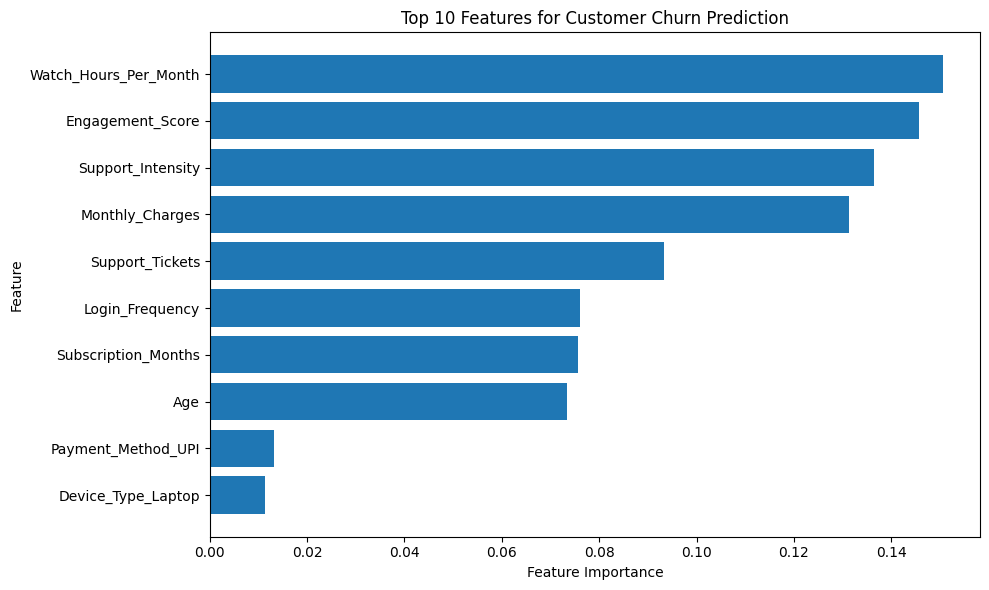

In [65]:
# ============================================================
# TOP 10 FEATURE IMPORTANCE GRAPH
# ============================================================

top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title(
    "Top 10 Features for Customer Churn Prediction"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
# ============================================================
# STRATIFIED K-FOLD CROSS-VALIDATION
# ============================================================

stratified_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(
    "Stratified K-Fold configured with 5 folds."
)

print("\nClass Distribution in Each Fold:")

fold_number = 1

for train_index, validation_index in stratified_kfold.split(
    X_selected,
    y
):

    y_validation = y.iloc[
        validation_index
    ]

    print(
        f"\nFold {fold_number}:"
    )

    print(
        y_validation.value_counts(
            normalize=True
        ).round(3)
    )

    fold_number += 1

Stratified K-Fold configured with 5 folds.

Class Distribution in Each Fold:

Fold 1:
Churned
0    0.504
1    0.496
Name: proportion, dtype: float64

Fold 2:
Churned
0    0.504
1    0.496
Name: proportion, dtype: float64

Fold 3:
Churned
1    0.5
0    0.5
Name: proportion, dtype: float64

Fold 4:
Churned
1    0.5
0    0.5
Name: proportion, dtype: float64

Fold 5:
Churned
1    0.5
0    0.5
Name: proportion, dtype: float64


In [67]:
# ============================================================
# LOGISTIC REGRESSION CROSS-VALIDATION
# ============================================================

cv_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

cv_scores = cross_val_score(
    cv_model,
    X_selected,
    y,
    cv=stratified_kfold,
    scoring="accuracy"
)

print(
    "Fold Accuracies:",
    np.round(cv_scores, 4)
)

print(
    "Mean CV Accuracy:",
    round(cv_scores.mean(), 4)
)

print(
    "CV Standard Deviation:",
    round(cv_scores.std(), 4)
)

Fold Accuracies: [0.7986 0.7554 0.7971 0.7899 0.8261]
Mean CV Accuracy: 0.7934
CV Standard Deviation: 0.0227


In [68]:
# ============================================================
# MODULE 3 FINAL CHECK
# ============================================================

print(
    "Total Processed Features:",
    X_processed_df.shape[1]
)

print(
    "Features Selected by RFE:",
    X_selected.shape[1]
)

print(
    "Mean Cross-Validation Accuracy:",
    round(cv_scores.mean(), 4)
)

print(
    "Cross-Validation Standard Deviation:",
    round(cv_scores.std(), 4)
)

print("\nModule 3 Completed Successfully!")

Total Processed Features: 19
Features Selected by RFE: 10
Mean Cross-Validation Accuracy: 0.7934
Cross-Validation Standard Deviation: 0.0227

Module 3 Completed Successfully!


# Module 4: Model Tuning and Baseline Algorithms

This module evaluates foundational machine learning models for customer churn prediction. Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN) are trained as baseline models. Hyperparameter optimization is performed using RandomizedSearchCV to identify an improved Decision Tree configuration.

In [69]:
# ============================================================
# TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Class Distribution:")
print(
    y_train.value_counts(normalize=True).round(3)
)

print("\nTesting Class Distribution:")
print(
    y_test.value_counts(normalize=True).round(3)
)

Training Features Shape: (553, 10)
Testing Features Shape: (139, 10)
Training Target Shape: (553,)
Testing Target Shape: (139,)

Training Class Distribution:
Churned
0    0.501
1    0.499
Name: proportion, dtype: float64

Testing Class Distribution:
Churned
0    0.504
1    0.496
Name: proportion, dtype: float64


In [70]:
# ============================================================
# BASELINE CLASSIFICATION MODELS
# ============================================================

baseline_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

baseline_results = {}

for name, model in baseline_models.items():

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    baseline_results[name] = accuracy

    print(
        f"{name} Accuracy: "
        f"{accuracy:.4f}"
    )

Logistic Regression Accuracy: 0.7626
Decision Tree Accuracy: 0.6619
KNN Accuracy: 0.7050


In [71]:
 # ============================================================
# BASELINE CROSS-VALIDATION COMPARISON
# ============================================================

baseline_cv_results = {}

for name, model in baseline_models.items():

    scores = cross_val_score(
        model,
        X_selected,
        y,
        cv=stratified_kfold,
        scoring="accuracy"
    )

    baseline_cv_results[name] = scores.mean()

    print(name)

    print(
        "Fold Accuracies:",
        np.round(scores, 4)
    )

    print(
        "Mean CV Accuracy:",
        round(scores.mean(), 4)
    )

    print("-" * 50)

Logistic Regression
Fold Accuracies: [0.7986 0.7554 0.7971 0.7899 0.8261]
Mean CV Accuracy: 0.7934
--------------------------------------------------
Decision Tree
Fold Accuracies: [0.6331 0.6187 0.6667 0.6739 0.6812]
Mean CV Accuracy: 0.6547
--------------------------------------------------
KNN
Fold Accuracies: [0.705  0.6978 0.7391 0.7319 0.7464]
Mean CV Accuracy: 0.7241
--------------------------------------------------


In [72]:
# ============================================================
# DECISION TREE HYPERPARAMETER TUNING
# ============================================================

dt_param_grid = {

    "criterion": [
        "gini",
        "entropy"
    ],

    "max_depth": [
        None,
        3,
        5,
        7,
        10,
        15,
        20
    ],

    "min_samples_split": [
        2,
        5,
        10,
        15,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        4,
        6,
        8
    ],

    "max_features": [
        None,
        "sqrt",
        "log2"
    ]
}


dt_random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),

    param_distributions=dt_param_grid,

    n_iter=25,

    scoring="accuracy",

    cv=stratified_kfold,

    random_state=42,

    n_jobs=-1
)


dt_random_search.fit(
    X_train,
    y_train
)


print("Best Decision Tree Parameters:")

print(
    dt_random_search.best_params_
)

print(
    "\nBest CV Accuracy:",
    round(
        dt_random_search.best_score_,
        4
    )
)

Best Decision Tree Parameters:
{'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 5, 'criterion': 'entropy'}

Best CV Accuracy: 0.7485


In [73]:
# ============================================================
# TUNED DECISION TREE EVALUATION
# ============================================================

best_dt_model = (
    dt_random_search.best_estimator_
)

tuned_dt_predictions = (
    best_dt_model.predict(X_test)
)

tuned_dt_accuracy = accuracy_score(
    y_test,
    tuned_dt_predictions
)


print(
    "Baseline Decision Tree Accuracy:",
    round(
        baseline_results["Decision Tree"],
        4
    )
)

print(
    "Tuned Decision Tree Accuracy:",
    round(
        tuned_dt_accuracy,
        4
    )
)


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        tuned_dt_predictions
    )
)


Baseline Decision Tree Accuracy: 0.6619
Tuned Decision Tree Accuracy: 0.6835

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.61      0.66        70
           1       0.66      0.75      0.70        69

    accuracy                           0.68       139
   macro avg       0.69      0.68      0.68       139
weighted avg       0.69      0.68      0.68       139



Confusion Matrix:
[[43 27]
 [17 52]]


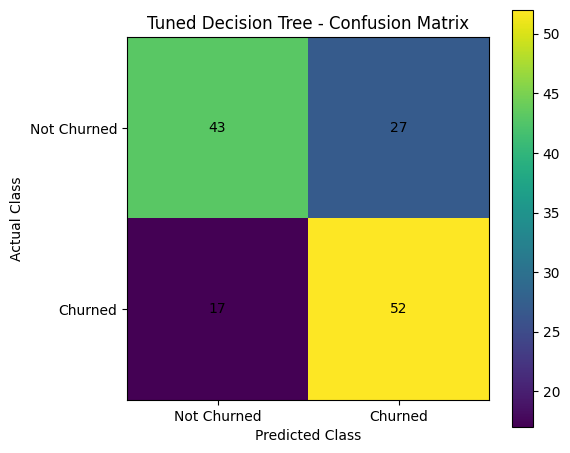

In [74]:
# ============================================================
# CONFUSION MATRIX - TUNED DECISION TREE
# ============================================================

cm = confusion_matrix(
    y_test,
    tuned_dt_predictions
)

print("Confusion Matrix:")
print(cm)


plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title(
    "Tuned Decision Tree - Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Not Churned", "Churned"]
)

plt.yticks(
    [0, 1],
    ["Not Churned", "Churned"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [75]:
# ============================================================
# MODULE 4 MODEL COMPARISON
# ============================================================

module4_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Tuned Decision Tree"
    ],

    "Test Accuracy": [
        baseline_results[
            "Logistic Regression"
        ],

        baseline_results[
            "Decision Tree"
        ],

        baseline_results[
            "KNN"
        ],

        tuned_dt_accuracy
    ],

    "Mean CV Accuracy": [
        baseline_cv_results[
            "Logistic Regression"
        ],

        baseline_cv_results[
            "Decision Tree"
        ],

        baseline_cv_results[
            "KNN"
        ],

        dt_random_search.best_score_
    ]
})


module4_results[
    "Test Accuracy (%)"
] = (
    module4_results[
        "Test Accuracy"
    ] * 100
).round(2)


module4_results[
    "Mean CV Accuracy (%)"
] = (
    module4_results[
        "Mean CV Accuracy"
    ] * 100
).round(2)


print(
    "Module 4 Model Comparison:"
)

display(
    module4_results.sort_values(
        "Test Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

Module 4 Model Comparison:


,Model,Test Accuracy,Mean CV Accuracy,Test Accuracy (%),Mean CV Accuracy (%)
0,Logistic Regression,0.762590,0.793400,76.26,79.34
1,KNN,0.705036,0.724054,70.50,72.41
2,Tuned Decision Tree,0.683453,0.748534,68.35,74.85
3,Decision Tree,0.661871,0.654708,66.19,65.47


In [76]:
# ============================================================
# MODULE 4 FINAL CHECK
# ============================================================

best_baseline_model = max(
    baseline_results,
    key=baseline_results.get
)

print(
    "Best Baseline Model:",
    best_baseline_model
)

print(
    "Best Baseline Test Accuracy:",
    round(
        baseline_results[
            best_baseline_model
        ],
        4
    )
)

print(
    "\nTuned Decision Tree Test Accuracy:",
    round(
        tuned_dt_accuracy,
        4
    )
)

print(
    "Tuned Decision Tree Best CV Accuracy:",
    round(
        dt_random_search.best_score_,
        4
    )
)

print(
    "\nModule 4 Completed Successfully!"
)

Best Baseline Model: Logistic Regression
Best Baseline Test Accuracy: 0.7626

Tuned Decision Tree Test Accuracy: 0.6835
Tuned Decision Tree Best CV Accuracy: 0.7485

Module 4 Completed Successfully!


# Module 5: Ensemble Models and Final Model Recommendation

This module evaluates ensemble learning algorithms for customer churn prediction. Random Forest and AdaBoost are trained and compared with the baseline models using test accuracy and Stratified K-Fold Cross-Validation.

The final model is selected by considering both test performance and cross-validation stability.

In [77]:
# ============================================================
# RANDOM FOREST CLASSIFIER
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(
    X_test
)

rf_test_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_cv_scores = cross_val_score(
    rf_model,
    X_selected,
    y,
    cv=stratified_kfold,
    scoring="accuracy"
)

print(
    "Random Forest Test Accuracy:",
    round(rf_test_accuracy, 4)
)

print(
    "Random Forest Mean CV Accuracy:",
    round(rf_cv_scores.mean(), 4)
)

print(
    "Random Forest CV Standard Deviation:",
    round(rf_cv_scores.std(), 4)
)

Random Forest Test Accuracy: 0.6978
Random Forest Mean CV Accuracy: 0.7255
Random Forest CV Standard Deviation: 0.0248


In [78]:
# ============================================================
# ADABOOST CLASSIFIER
# ============================================================

ada_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.8,
    random_state=42
)

ada_model.fit(
    X_train,
    y_train
)

ada_predictions = ada_model.predict(
    X_test
)

ada_test_accuracy = accuracy_score(
    y_test,
    ada_predictions
)

ada_cv_scores = cross_val_score(
    ada_model,
    X_selected,
    y,
    cv=stratified_kfold,
    scoring="accuracy"
)

print(
    "AdaBoost Test Accuracy:",
    round(ada_test_accuracy, 4)
)

print(
    "AdaBoost Mean CV Accuracy:",
    round(ada_cv_scores.mean(), 4)
)

print(
    "AdaBoost CV Standard Deviation:",
    round(ada_cv_scores.std(), 4)
)

AdaBoost Test Accuracy: 0.7266
AdaBoost Mean CV Accuracy: 0.7632
AdaBoost CV Standard Deviation: 0.0468


In [79]:
# ============================================================
# ENSEMBLE MODEL CLASSIFICATION REPORTS
# ============================================================

print("=" * 60)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        rf_predictions
    )
)


print("=" * 60)
print("ADABOOST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        ada_predictions
    )
)

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.69      0.71      0.70        70
           1       0.70      0.68      0.69        69

    accuracy                           0.70       139
   macro avg       0.70      0.70      0.70       139
weighted avg       0.70      0.70      0.70       139

ADABOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.74      0.71      0.72        70
           1       0.72      0.74      0.73        69

    accuracy                           0.73       139
   macro avg       0.73      0.73      0.73       139
weighted avg       0.73      0.73      0.73       139



In [80]:
# ============================================================
# CROSS-VALIDATION COMPARISON OF ALL MODELS
# ============================================================

final_models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=5
        ),

    "Tuned Decision Tree":
        best_dt_model,

    "Random Forest":
        rf_model,

    "AdaBoost":
        ada_model
}


final_cv_results = []

for name, model in final_models.items():

    scores = cross_val_score(
        model,
        X_selected,
        y,
        cv=stratified_kfold,
        scoring="accuracy"
    )

    final_cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })


final_cv_df = pd.DataFrame(
    final_cv_results
)

final_cv_df[
    "Mean CV Accuracy (%)"
] = (
    final_cv_df[
        "Mean CV Accuracy"
    ] * 100
).round(2)

final_cv_df[
    "CV Standard Deviation (%)"
] = (
    final_cv_df[
        "CV Standard Deviation"
    ] * 100
).round(2)


final_cv_df = final_cv_df.sort_values(
    "Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)


print(
    "Cross-Validation Comparison:"
)

display(final_cv_df)

Cross-Validation Comparison:


,Model,Mean CV Accuracy,CV Standard Deviation,Mean CV Accuracy (%),CV Standard Deviation (%)
0,Logistic Regression,0.793400,0.022652,79.34,2.27
1,AdaBoost,0.763153,0.046777,76.32,4.68
2,Random Forest,0.725451,0.024789,72.55,2.48
3,KNN,0.724054,0.019161,72.41,1.92
4,Tuned Decision Tree,0.692107,0.046493,69.21,4.65
5,Decision Tree,0.654708,0.024392,65.47,2.44


In [81]:
# ============================================================
# FINAL TEST ACCURACY COMPARISON
# ============================================================

final_test_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Tuned Decision Tree",
        "Random Forest",
        "AdaBoost"
    ],

    "Test Accuracy": [

        baseline_results[
            "Logistic Regression"
        ],

        baseline_results[
            "Decision Tree"
        ],

        baseline_results[
            "KNN"
        ],

        tuned_dt_accuracy,

        rf_test_accuracy,

        ada_test_accuracy
    ]
})


final_test_results[
    "Test Accuracy (%)"
] = (
    final_test_results[
        "Test Accuracy"
    ] * 100
).round(2)


final_test_results = (
    final_test_results
    .sort_values(
        "Test Accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "Final Test Accuracy Comparison:"
)

display(final_test_results)

Final Test Accuracy Comparison:


,Model,Test Accuracy,Test Accuracy (%)
0,Logistic Regression,0.762590,76.26
1,AdaBoost,0.726619,72.66
2,KNN,0.705036,70.50
3,Random Forest,0.697842,69.78
4,Tuned Decision Tree,0.683453,68.35
5,Decision Tree,0.661871,66.19


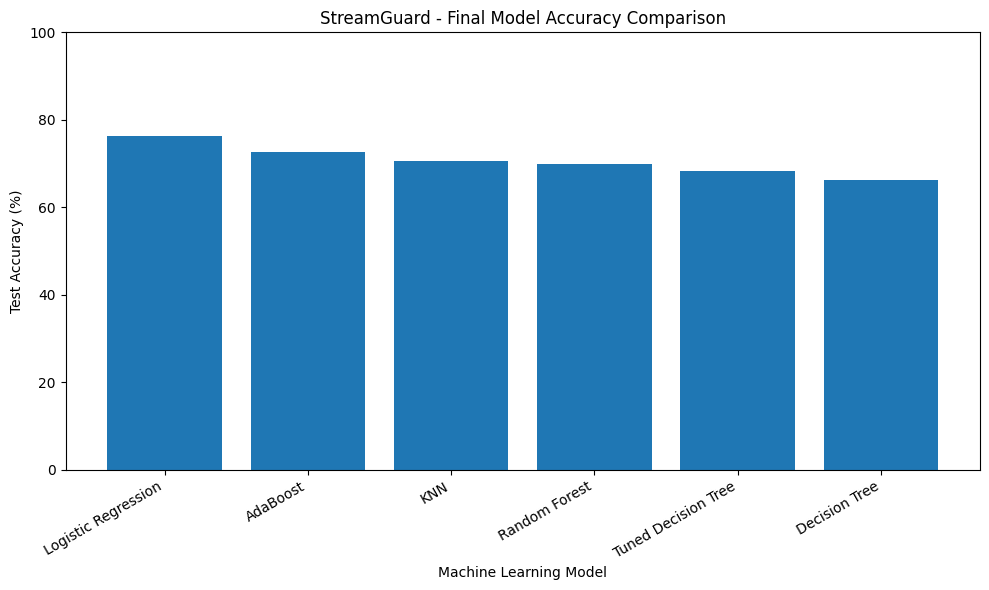

In [82]:
# ============================================================
# FINAL MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    final_test_results["Model"],
    final_test_results["Test Accuracy (%)"]
)

plt.title(
    "StreamGuard - Final Model Accuracy Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(
    0,
    100
)

plt.tight_layout()
plt.show()

In [83]:
# ============================================================
# IDENTIFY BEST TEST AND CROSS-VALIDATION MODELS
# ============================================================

best_test_row = (
    final_test_results.iloc[0]
)

best_cv_row = (
    final_cv_df.iloc[0]
)


print(
    "Best Model Based on Test Accuracy:"
)

print(
    best_test_row["Model"],
    "-",
    f'{best_test_row["Test Accuracy (%)"]:.2f}%'
)


print(
    "\nBest Model Based on Cross-Validation:"
)

print(
    best_cv_row["Model"],
    "-",
    f'{best_cv_row["Mean CV Accuracy (%)"]:.2f}%'
)

Best Model Based on Test Accuracy:
Logistic Regression - 76.26%

Best Model Based on Cross-Validation:
Logistic Regression - 79.34%


In [84]:
# ============================================================
# FINAL MODEL RECOMMENDATION
# ============================================================

best_model_name = (
    best_cv_row["Model"]
)

best_model_cv = (
    best_cv_row["Mean CV Accuracy (%)"]
)


print("=" * 65)
print("STREAMGUARD FINAL MODEL RECOMMENDATION")
print("=" * 65)

print(
    "\nRecommended Model:",
    best_model_name
)

print(
    "Mean Cross-Validation Accuracy:",
    f"{best_model_cv:.2f}%"
)

print(
    "\nThe final recommendation prioritizes "
    "cross-validation performance because it provides "
    "a more reliable estimate of how the model generalizes "
    "across different subsets of customer data."
)

STREAMGUARD FINAL MODEL RECOMMENDATION

Recommended Model: Logistic Regression
Mean Cross-Validation Accuracy: 79.34%

The final recommendation prioritizes cross-validation performance because it provides a more reliable estimate of how the model generalizes across different subsets of customer data.


## Model Strengths and Weaknesses

**Logistic Regression:**  
Simple, fast, interpretable, and useful as a strong baseline model. However, it may struggle with highly complex non-linear relationships.

**Decision Tree:**  
Easy to understand and capable of modeling non-linear relationships. However, an unrestricted tree can overfit the training data.

**K-Nearest Neighbors (KNN):**  
Simple and capable of identifying local patterns in customer behavior. However, its performance can decrease with larger datasets and high-dimensional feature spaces.

**Random Forest:**  
Combines multiple decision trees and generally provides better stability and resistance to overfitting than a single Decision Tree. However, it is less interpretable and computationally more expensive.

**AdaBoost:**  
Sequentially focuses on incorrectly classified observations and can achieve strong predictive performance. However, it can be sensitive to noisy observations and outliers.

The final production recommendation should consider both predictive performance and cross-validation stability rather than relying only on a single train-test split.

# Final Conclusion

Project StreamGuard successfully developed an end-to-end machine learning pipeline for predicting customer churn in a subscription-based streaming environment.

The project included data exploration, missing-value treatment, IQR-based outlier handling, feature engineering, One-Hot Encoding, Z-Score Standardization, Recursive Feature Elimination, feature-importance analysis, Stratified K-Fold Cross-Validation, baseline model evaluation, RandomizedSearchCV hyperparameter tuning, and ensemble learning.

A customer Engagement Score and Support Intensity feature were engineered to capture meaningful behavioral patterns. RFE was then used to retain the most predictive variables.

Logistic Regression, Decision Tree, KNN, Random Forest, and AdaBoost were evaluated. A tuned Decision Tree was also produced using RandomizedSearchCV.

The final model should be selected primarily using mean Stratified K-Fold Cross-Validation accuracy while also considering test accuracy and model stability. This provides a more reliable estimate of expected performance on unseen subscription customers.

Overall, Project StreamGuard demonstrates a complete machine learning workflow for identifying customers at risk of churn and provides a foundation for data-driven customer-retention strategies.

In [85]:
# ============================================================
# PROJECT STREAMGUARD - FINAL CHECK
# ============================================================

print("=" * 65)
print("PROJECT STREAMGUARD - FINAL SUMMARY")
print("=" * 65)

print(
    "\nFinal Dataset Shape:",
    df.shape
)

print(
    "Selected Features:",
    X_selected.shape[1]
)

print(
    "Training Samples:",
    X_train.shape[0]
)

print(
    "Testing Samples:",
    X_test.shape[0]
)

print(
    "\nBest Test Model:",
    best_test_row["Model"]
)

print(
    "Best Test Accuracy:",
    f'{best_test_row["Test Accuracy (%)"]:.2f}%'
)

print(
    "\nBest CV Model:",
    best_cv_row["Model"]
)

print(
    "Best Mean CV Accuracy:",
    f'{best_cv_row["Mean CV Accuracy (%)"]:.2f}%'
)

print(
    "\nPROJECT STREAMGUARD COMPLETED SUCCESSFULLY!"
)

PROJECT STREAMGUARD - FINAL SUMMARY

Final Dataset Shape: (692, 12)
Selected Features: 10
Training Samples: 553
Testing Samples: 139

Best Test Model: Logistic Regression
Best Test Accuracy: 76.26%

Best CV Model: Logistic Regression
Best Mean CV Accuracy: 79.34%

PROJECT STREAMGUARD COMPLETED SUCCESSFULLY!
